In [128]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy import constants
import matplotlib.pyplot as plt
import camb
MP2 = 1

def omega_r(h):
    ab = (8*constants.pi**5*constants.k**4)/(15*constants.h**3*constants.c**3)
    rhor = ab*2.7255**4/(constants.c**2)
    rhov = 3.046*(7/8)*(4/11)**(4/3)*rhor
    return((rhor+rhov)/((3*(100*h)**2/(8*constants.pi*constants.G))*(1000)**2/(10**6*constants.parsec)**2))

def aseries(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2)*tau)/(a0**2*mups2*(-1 + \
            4*stigma))**(1/2) + (2500*h**2*tau**2*(omega_m))/(a0*mups2) + \
            (15625*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(-2 + stigma*(5 + \
            24*stigma))*tau**3*(omega_m)**2)/(a0*mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) + (390625*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**4*(omega_m)**3)/(2*a0*mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def cpseries(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
       1 - (25*h*(-1 + \
            4*stigma)**(1/2)*tau*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
            4*stigma)*(2 + stigma*(-2 + \
            3*stigma))*tau**2*(omega_m)**2)/(8*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 \
            + stigma + 8*stigma**2)) + (15625*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
            stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
            + 48*stigma))))))*tau**3*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
            + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def cpseriesp(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (-25*h*(-1 + \
        4*stigma)**(1/2)*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
        4*stigma)*(2 + stigma*(-2 + \
        3*stigma))*tau*(omega_m)**2)/(4*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 + \
        stigma + 8*stigma**2)) + (46875*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
        stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
        + 48*stigma))))))*tau**2*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
        + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def aseriesp(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2))/(a0**2*mups2*(-1 + \
            4*stigma))**(1/2) + (5000*h**2*tau*(omega_m))/(a0*mups2) + \
            (46875*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(-2 + stigma*(5 + \
            24*stigma))*tau**2*(omega_m)**2)/(a0*mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) + (781250*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**3*(omega_m)**3)/(a0*mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

    
def P_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    return((MP2*(10000*cp**9*da*h**2*(-1 + 4*stigma**2)**3*(4*a**4*a0**4*OmL + \
            mups2*omega_r(h) + a*a0*(omega_m)) + 2*a*dcp*stigma**3*(-1 + 2*stigma)*(1 + \
            2*stigma)*(-7 + 4*stigma)*(a**2*a0**2*dcp**2*mups2 + \
            40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + \
            2*a*cp**6*dcp*(1 - 4*stigma**2)**2*(a**2*a0**2*dcp**2*mups2*(1 - \
            4*stigma**2) + 40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + \
            a*a0*(omega_m))) - 2*a*cp**2*dcp*stigma**2*(-1 + \
            4*stigma**2)*(-(a**2*a0**2*dcp**2*mups2*(5 + 8*stigma*(1 + 2*(-2 + \
            stigma)*stigma))) + 40000*h**2*stigma*(-5 + 2*stigma)*(1 + \
            2*stigma)*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + \
            2*a*cp**4*dcp*stigma*(-(a**2*a0**2*dcp**2*mups2*(3 + 4*(-3 + \
            stigma)*stigma)*(1 - 4*stigma**2)**2) - 120000*h**2*stigma*(-1 + \
            2*stigma)*(1 + 2*stigma)*(-1 + 4*stigma)*(a**4*a0**4*OmL + omega_r(h) + \
            a*a0*(omega_m))) + cp*da*stigma**3*(-(a**2*a0**2*dcp**2*mups2*(-1 + \
            2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-19 + 8*stigma))) - \
            10000*h**2*stigma*(-5 + 8*stigma)*(8*a**4*a0**4*OmL*(-1 + stigma)*(1 + \
            2*stigma) + 4*omega_r(h)*(3 + 2*stigma*(-5 + 2*stigma)) + a*a0*(-7 + \
            4*stigma)*(-1 + 4*stigma)*(omega_m))) - cp**7*da*(1 - \
            4*stigma**2)**2*(3*a**2*a0**2*dcp**2*mups2*(-1 + 4*stigma**2) + \
            10000*h**2*stigma*(4*a**4*a0**4*OmL*(-11 + 2*stigma*(9 + stigma)) + \
            omega_r(h)*(4 - 8*(-1 + stigma)*stigma + mups2*(-11 + 4*stigma*(4 + stigma))) \
            - 4*a*a0*(2 + (-6 + stigma)*stigma)*(omega_m))) + \
            cp**3*da*stigma**2*(10000*h**2*omega_r(h)*stigma*(-92 - mups2*(5 - \
            8*stigma)**2*(-1 + 4*stigma**2) + 8*stigma*(21 + stigma*(69 + \
            4*stigma*(-41 + 18*stigma)))) + a*a0*(a*a0*dcp**2*mups2*(-1 + \
            2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-1 + stigma*(-31 + 12*stigma))) \
            + 40000*h**2*stigma*(a**3*a0**3*OmL*(37 + 2*stigma*(-67 + 7*stigma*(9 \
            + 4*stigma - 8*stigma**2))) + (-2 + 5*stigma)*(4 + stigma*(11 + \
            8*stigma*(-5 + 2*stigma)))*(omega_m)))) + cp**5*da*stigma*(-1 + \
            4*stigma**2)*(10000*h**2*omega_r(h)*stigma*(mups2*(-5 + 8*stigma)*(-7 + \
            8*stigma*(1 + stigma)) - 4*(9 + 2*stigma*(1 + 2*stigma*(-13 + \
            8*stigma)))) + a*a0*(3*a*a0*dcp**2*mups2*(1 - 16*(stigma - \
            4*stigma**3 + stigma**4)) + 20000*h**2*stigma*(2*a**3*a0**3*OmL*(37 + \
            2*stigma*(-57 + 4*stigma*(9 + 4*stigma))) + (5 - 2*stigma*(30 + \
            stigma*(-57 + \
            16*stigma)))*(omega_m))))))/(a**4*cp**3*da*mups2*(-cp**2 + \
            stigma)*(-1 + 4*stigma**2)*((5 - 8*stigma)*stigma + cp**2*(-1 + \
            4*stigma**2))**2))
    
def rho_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    return((3*MP2*(-10000*h**2*omega_r(h) - 10000*a*h**2*(omega_m) + \
            (-(a**2*a0**2*dcp**2*mups2*(-stigma + cp**2*(1 - 4*stigma**2))) - \
            2*a*a0**2*cp*da*dcp*mups2*(stigma*(-1 + 4*stigma) + cp**2*(1 - \
            4*stigma**2)) + 40000*h**2*stigma*(-cp**2 + stigma)*(a**4*a0**4*OmL \
            + omega_r(h) + a*a0*(omega_m)))/(-(cp**2*mups2*(5 - 8*stigma)*stigma) - \
            cp**4*mups2*(-1 + 4*stigma**2))))/a**4)


def ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (-1/8*(120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + \
            stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) - \
            40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + \
            cp**2*(-1 + 4*stigma**2)) + a0**2*cp**2*da**2*mups2*((5 - \
            8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
            4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
            cp**4*(-1 + 4*stigma**2)) + a**2*a0**2*dcp**2*mups2*(stigma**3*(-1 + \
            4*stigma)*(1 + 8*stigma) + cp**4*stigma*(-1 + 2*stigma)*(1 + \
            2*stigma)*(3 + 4*(-3 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            cp**2*stigma**2*(3 - 8*(stigma + 2*stigma**3))) + \
            2*a*a0**2*cp*da*dcp*mups2*(cp**4*stigma*(-1 + 2*stigma)*(1 + \
            2*stigma)*(11 + 4*(-4 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            stigma**3*(-1 + 16*stigma*(-2 + 3*stigma)) + cp**2*stigma**2*(11 - \
            16*stigma*(1 + stigma*(-1 + \
            2*stigma)))))/(a**2*a0**2*cp*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
            4*stigma**2)))
    return val

def dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (-1/8*(-(a**2*a0**2*dcp**2*mups2*(3*cp**2*stigma**2 + cp**4*(1 - \
            2*stigma)**2*stigma*(-3 + 2*stigma)*(1 + 2*stigma) - stigma**3*(1 + \
            8*stigma) + cp**6*(1 - 4*stigma**2)**2)) - \
            120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma + \
            cp**2*(-1 + 4*stigma**2)) + 40000*h**2*omega_r(h)*stigma*(-cp**2 + \
            stigma)**2*(stigma + cp**2*(-1 + 4*stigma**2)) - \
            2*a*a0**2*cp*da*dcp*mups2*(stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
            4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
            cp**4*(-1 + 4*stigma**2)) - a0**2*cp**2*da**2*mups2*(cp**4*(1 - \
            2*stigma)**2*stigma*(-7 + 2*stigma)*(1 + 2*stigma) + stigma**3*(3 + \
            32*(-1 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            cp**2*stigma**2*(3 - 16*(-1 + stigma)*stigma*(-1 + \
            2*stigma))))/(a*a0**2*cp**2*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
            4*stigma**2)))
    return val

def coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2):
    a, cp, da, dcp = y
    dydt = [da, dcp, dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2), ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2)]
    return dydt

#Initial conditions
def small(omega_m, h, stigma, mups2):
    val = 1e-6*(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2))/(25*h*(-1 + 4*stigma)**(1/2)*(omega_m))
    return val

#Stops for Solve_ivp
def hstop(h):
    def event(t, y):
        return y[2]-h*100
    event.terminal = True
    event.direction = 1
    return event

def astop(t, y):
    return y[0]-1

astop.terminal = True
astop.direction = 1

def rhopsol(omega_m, h, OmL, stigma, mups2):

    tauini = small(omega_m, h, stigma, mups2)
    print(tauini)

    a0 = 1
    
    y02 = [aseries(tauini, omega_m, h, OmL, a0, stigma, mups2), cpseries(tauini, omega_m, h, OmL, a0, stigma, mups2),
          aseriesp(tauini, omega_m, h, OmL, a0, stigma, mups2), cpseriesp(tauini, omega_m, h, OmL, a0, stigma, mups2)]
    
    sola0 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2),
                    [tauini, np.inf], y02, events = astop, rtol=1e-8, atol=1e-8)
    
    tsol = interp1d(sola0.y[0], sola0.t, bounds_error = False)
    avals = np.logspace(np.log10(sola0.y[0][0]),0,10000)
    tvals = tsol(avals)
    tvals[0] = tauini
    avals[0] = sola0.y[0][0]
    
    
    sola02 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2),
                    [tauini, np.inf], y02, t_eval = tvals, events = astop, rtol=1e-8, atol=1e-8)
    
    asol, varpisol, hsol, dvarpisol = sola02.y
    aend, vpend, hend, dvpend = sola02.y_events[0][0]

    if aend > asol[-1]:
        asol = np.append(asol, aend)
        hsol = np.append(hsol, hend)
        varpisol = np.append(varpisol, vpend)
        dvarpisol = np.append(dvarpisol, dvpend)

    hubble = (a0* hsol)/asol**2
    z = 1/asol-1
    
    return z[::-1], hubble[::-1],  asol

2.433597956300554e-09


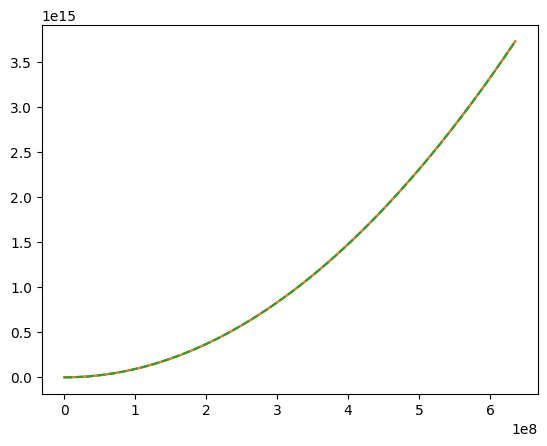

In [129]:
h = 0.7
H0 = 100*h
stigma = 1.0001
mups2 = 4/3
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2
OmL = (1-omega_m-omega_r(h))
c_kms = 299792.458  # km/s
omegar = omega_r(h)

z, hubble, P_DE, rho_DE, asol = rhopsol(omega_m, h, OmL, stigma, mups2)

h_interp = interp1d(z, hubble / hubble[0], kind='cubic')

plt.plot(z, hubble/hubble[0])
plt.plot(z, h_interp(z))
plt.plot(z, E_lcdm(z, omega_m), "--")

def E_lcdm(z, omegam):
    return np.sqrt(omegam*(1+z)**3 + omegar*(1+z)**4 + OmL)



(0.0, 3.0)

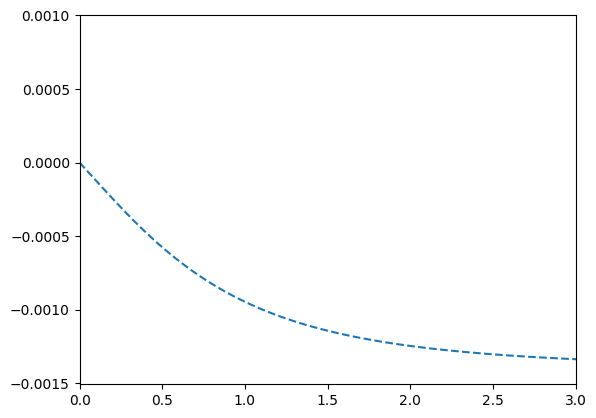

In [130]:
plt.plot(z, h_interp(z)/E_lcdm(z, omega_m)-1, "--")
plt.xlim(0, 3)

Text(0, 0.5, '$E_\\mathrm{theory}/E_{\\Lambda\\mathrm{CDM}} - 1$')

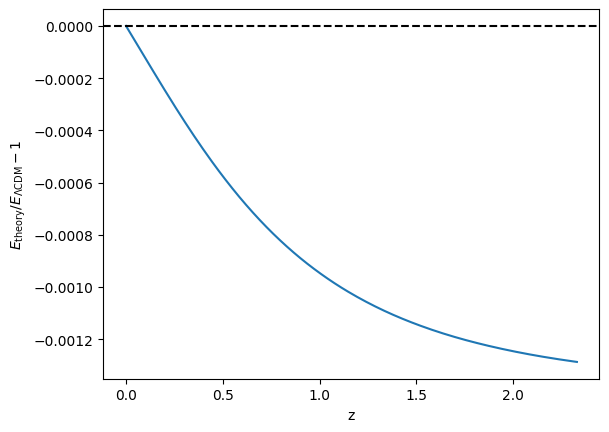

In [131]:
z_test = np.linspace(1e-15, max(zv_all), 200)

E_theory = np.array([float(h_interp(z)) for z in z_test])
E_ref = np.array([E_lcdm(z, omega_m) for z in z_test])

plt.plot(z_test, E_theory / E_ref - 1)
plt.axhline(0, color='k', ls='--')
plt.xlabel("z")
plt.ylabel(r"$E_\mathrm{theory}/E_{\Lambda\mathrm{CDM}} - 1$")

In [132]:
omegam_bf

np.float64(0.29685378761847714)

ΛCDM best fit: H0rd = 10157.5 km/s,  Ωm = 0.2969
2.3676907901077764e-09


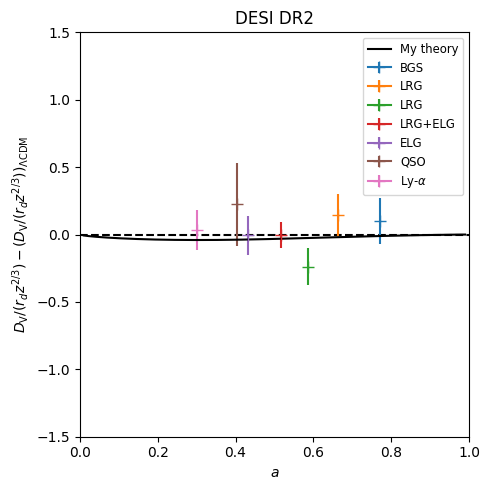

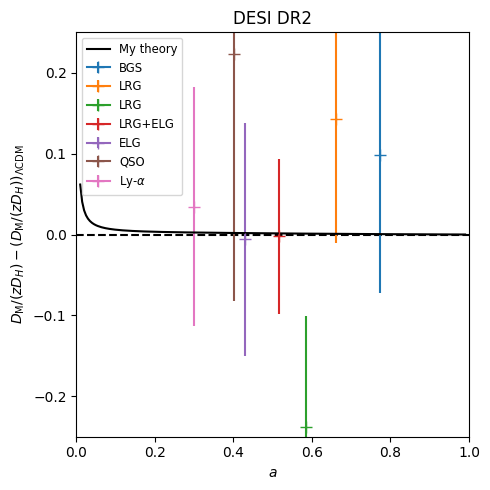

In [133]:
import numpy as np
from scipy.stats import multivariate_normal
from scipy.integrate import quad
from scipy.optimize import minimize
from pandas import read_csv
import matplotlib
import matplotlib.pyplot as plt

h = 0.7
H0 = 100*h
stigma = 1.01
mups2 = 4/3
c_kms = 299792.458  # km/s
omegar = omega_r(h)

# ── Load DESI DR2 data ────────────────────────────────────────────────────────

# Load DESI DR2 data
data = read_csv("../../data/desidr2/desidr2_mean.txt",
                header=None, index_col=None, sep=r"\s+", comment="#")
cov = np.loadtxt("../../data/desidr2/desidr2_cov.txt")

zs = data.iloc[:, 0].to_numpy()
mean_data = data.iloc[:, 1].to_numpy()
types = data.iloc[:, 2].to_numpy()
cov_inv = np.linalg.inv(cov)

def E_lcdm(z, omegam):
    return np.sqrt(omegam*(1+z)**3 + omegar*(1+z)**4 + (1-omegam-omegar))

def dm_lcdm(z, h0rd, omegam):
    integral, _ = quad(lambda zp: 1/E_lcdm(zp, omegam), 0, z)
    return c_kms / h0rd * integral

def dh_lcdm(z, h0rd, omegam):
    return c_kms / h0rd / E_lcdm(z, omegam)

def dv_lcdm(z, h0rd, omegam):
    return (z * dm_lcdm(z, h0rd, omegam)**2 * dh_lcdm(z, h0rd, omegam))**(1/3)

def chi2_lcdm(params):
    h0rd, omegam = params
    if omegam <= 0 or omegam >= 1 or h0rd <= 0:
        return 1e10
    fns = {"DM_over_rs": dm_lcdm, "DH_over_rs": dh_lcdm, "DV_over_rs": dv_lcdm}
    pred = [fns[t](z, h0rd, omegam) for z, t in zip(zs, types)]
    return (mean_data - pred) @ cov_inv @ (mean_data - pred)

result = minimize(chi2_lcdm, x0=[10145, 0.298], method='Nelder-Mead',
                  options={'xatol': 1e-6, 'fatol': 1e-8, 'maxiter': 10000})
h0rd_bf, omegam_bf = result.x
print(f"ΛCDM best fit: H0rd = {h0rd_bf:.1f} km/s,  Ωm = {omegam_bf:.4f}")

def lcdm_ratio(z):
    integral, _ = quad(lambda zp: 1/E_lcdm(zp, omegam_bf), 0, z)
    return E_lcdm(z, omegam_bf) * integral / z
def lcdm_dv_over_rdz23(z):
    return dv_lcdm(z, h0rd_bf, omegam_bf) / z**(2/3)

omega_m = omegam_bf
OmL = (1-omega_m-omega_r(h))

# ── Sample from covariance ────────────────────────────────────────────────────

np.random.seed(42)
samples = multivariate_normal(mean_data, cov).rvs(10_000)

dmidx = types == "DM_over_rs"
dhidx = types == "DH_over_rs"
dvidx = types == "DV_over_rs"

dm_s = samples[:, dmidx]   # shape (10000, 6) — DM/rs at 6 redshifts
dh_s = samples[:, dhidx]   # shape (10000, 6) — DH/rs at 6 redshifts
dv_s = samples[:, dvidx]   # shape (10000, 1) — DV/rs for BGS only

zm = zs[dmidx]          # redshifts with DM and DH measurements
zv_bgs = zs[dvidx]      # BGS redshift (z=0.295)

# DV/rs for non-BGS tracers: (z * (DM/rs)^2 * (DH/rs))^(1/3)
dv_derived = (zm * dm_s**2 * dh_s)**(1/3)   # shape (10000, 6)

# Combine BGS DV with derived DV, then sort by redshift
zv_all = np.concatenate([zv_bgs, zm])
dv_all = np.hstack([dv_s, dv_derived])       # shape (10000, 7)

sort_idx = np.argsort(zv_all)
zv_all = zv_all[sort_idx]
dv_all = dv_all[:, sort_idx]

# DV / (rs * z^(2/3))
ratio = dv_all / zv_all**(2/3)
ratio_mean = ratio.mean(axis=0)
ratio_std = ratio.std(axis=0)

lcdm_pred = np.array([lcdm_dv_over_rdz23(z) for z in zv_all])
residuals = ratio_mean - lcdm_pred



%matplotlib inline 
# ── Plot ──────────────────────────────────────────────────────────────────────

# C0-C6 in standard order: BGS, LRG, LRG, LRG+ELG, ELG, QSO, Ly-α
labels = ["BGS", "LRG", "LRG", "LRG+ELG", "ELG", "QSO", r"Ly-$\alpha$"]
colors = [f"C{i}" for i in range(7)]
a_vals = 1 / (1 + zv_all)

fig, ax = plt.subplots(figsize=(5, 5))
ax.axhline(0, color='k', linestyle='--')

for a, res, err, label, color in zip(a_vals, residuals, ratio_std, labels, colors):
    ax.errorbar(a, res, yerr=err, marker='+', markersize=8, linewidth=1.5,
                color=color, label=label, capsize=0)

ax.set(
    xlabel=r'$a$',
    ylabel=r'$D_\mathrm{V}/(r_d z^{2/3}) - (D_\mathrm{V}/(r_d z^{2/3}))_{\Lambda\mathrm{CDM}}$',
    xlim=(0, 1),
    ylim=(-1.5, 1.5),
    title='DESI DR2',
)



z_arr, H_arr,P_DE, rho_DE, asol = rhopsol(omega_m, h, OmL, stigma, mups2)
h_interp = interp1d(z_arr, H_arr / H_arr[0], kind='cubic')


def theory_dv_over_rdz23(z):
    integral, _ = quad(lambda zp: 1/float(h_interp(zp)), 0, z)
    dm = c_kms / h0rd_bf * integral
    dh = c_kms / h0rd_bf / float(h_interp(z))
    return (z * dm**2 * dh)**(1/3) / z**(2/3)

a_plot = np.linspace(0.01, 0.99, 2000)
z_plot = 1/a_plot - 1
theory_res = np.array([theory_dv_over_rdz23(z) - lcdm_dv_over_rdz23(z) for z in z_plot])
ax.plot(a_plot, theory_res, color='k', linewidth=1.5, label='My theory')

# ─────────────────────────────────────────────────────────────────────────────


ax.legend(fontsize='small')
fig.tight_layout()

def theory_ratio(z):
    integral, _ = quad(lambda zp: 1/float(h_interp(zp)), 0, z)
    return float(h_interp(z)) * integral / z


# ── 5. PLOT ───────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(5, 5))
ax.axhline(0, color='k', linestyle='--')

for a, res, err, label, color in zip(a_vals, residuals, ratio_std, labels, colors):
    ax.errorbar(a, res, yerr=err, marker='+', markersize=8, linewidth=1.5,
                color=color, label=label, capsize=0)

a_plot = np.linspace(0.01, 0.99, 200)
z_plot = 1 / a_plot - 1
theory_res = np.array([theory_ratio(z) - lcdm_ratio(z) for z in z_plot])
ax.plot(a_plot, theory_res, color='k', linewidth=1.5, label='My theory')

ax.set(
    xlabel=r'$a$',
    ylabel=r'$D_\mathrm{M}/(zD_H) - (D_\mathrm{M}/(zD_H))_{\Lambda\mathrm{CDM}}$',
    xlim=(0, 1),
    ylim=(-0.25, 0.25),
    title='DESI DR2',
)
ax.legend(fontsize='small')
fig.tight_layout()

Text(0, 0.5, '$E_\\mathrm{theory}/E_{\\Lambda\\mathrm{CDM}} - 1$')

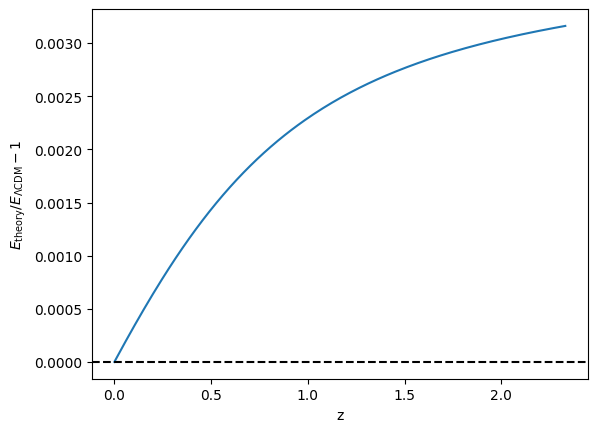

In [134]:
z_test = np.linspace(3e-15, max(zv_all), 200)

E_theory = np.array([float(h_interp(z)) for z in z_test])
E_ref = np.array([E_lcdm(z, omegam_bf) for z in z_test])

plt.plot(z_test, E_theory / E_ref - 1)
plt.axhline(0, color='k', ls='--')
plt.xlabel("z")
plt.ylabel(r"$E_\mathrm{theory}/E_{\Lambda\mathrm{CDM}} - 1$")

In [46]:
z_arr, H_arr,P_DE, rho_DE, asol = rhopsol(omega_m, h, OmL, stigma, mups2)
h_interp = interp1d(z_arr, H_arr / H_arr[0], kind='cubic')
pars = camb.CAMBparams()
pars.set_cosmology(H0=H0, ombh2=ombh2, omch2=0.2969*h**2-ombh2, omk=0)
pars.set_dark_energy_rho_p_a(a_p=asol, a_rho=asol,p=P_DE, rho=rho_DE)
pars.set_for_lmax(2500, lens_potential_accuracy=0)
pars.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)

results = camb.get_background(pars)
rd_theory      = results.get_derived_params()['rdrag']  # Mpc
h0rd_theory    = H0 * rd_theory
print(h0rd_theory)

2.371590699656001e-09
10236.750775482631


In [34]:
pars2 = camb.CAMBparams()
pars2.set_cosmology(H0=H0, ombh2=ombh2, omch2=omch2, omk=0)
pars2.set_for_lmax(2500, lens_potential_accuracy=0)
pars2.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)

results2 = camb.get_background(pars2)
rd_bg     = results2.get_derived_params()['rdrag']  # Mpc
h0rd_bg    = H0 * rd_bg                      
print(h0rd_bg)

10305.604592807918


2.3715551306270104e-09
[np.float64(1.5339345894267629e-09), np.float64(0.9999990074988753), np.float64(0.6468060440923047), np.float64(-415.34022831348307)]


CAMBError: Error in Fortran called from calc_background:
Universe stops expanding before today (recollapse not supported)

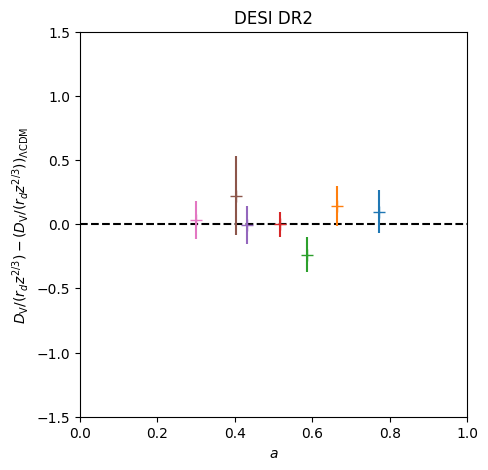

In [35]:
%matplotlib inline 
# ── Plot ──────────────────────────────────────────────────────────────────────

# C0-C6 in standard order: BGS, LRG, LRG, LRG+ELG, ELG, QSO, Ly-α
labels = ["BGS", "LRG", "LRG", "LRG+ELG", "ELG", "QSO", r"Ly-$\alpha$"]
colors = [f"C{i}" for i in range(7)]
a_vals = 1 / (1 + zv_all)

fig, ax = plt.subplots(figsize=(5, 5))
ax.axhline(0, color='k', linestyle='--')

for a, res, err, label, color in zip(a_vals, residuals, ratio_std, labels, colors):
    ax.errorbar(a, res, yerr=err, marker='+', markersize=8, linewidth=1.5,
                color=color, label=label, capsize=0)

ax.set(
    xlabel=r'$a$',
    ylabel=r'$D_\mathrm{V}/(r_d z^{2/3}) - (D_\mathrm{V}/(r_d z^{2/3}))_{\Lambda\mathrm{CDM}}$',
    xlim=(0, 1),
    ylim=(-1.5, 1.5),
    title='DESI DR2',
)



z_arr, H_arr,P_DE, rho_DE, asol = rhopsol(omega_m, h, OmL, stigma, mups2)
h_interp = interp1d(z_arr, H_arr / H_arr[0], kind='cubic')
pars = camb.CAMBparams()
pars.set_cosmology(H0=H0, ombh2=ombh2, omch2=omch2, omk=0)
pars.set_dark_energy_rho_p_a(a_p=asol, a_rho=asol,p=P_DE, rho=rho_DE)
pars.set_for_lmax(2500, lens_potential_accuracy=0)
pars.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)

results = camb.get_background(pars)
rd_theory      = results.get_derived_params()['rdrag']  # Mpc
h0rd_theory    = H0 * rd_theory                        
print(h0rd_theory)

def theory_dv_over_rdz23(z):
    integral, _ = quad(lambda zp: 1/float(h_interp(zp)), 0, z)
    dm = c_kms / h0rd_bf * integral
    dh = c_kms / h0rd_bf / float(h_interp(z))
    return (z * dm**2 * dh)**(1/3) / z**(2/3)
print(h0rd_theory, h0rd_bf)
a_plot = np.linspace(0.01, 0.99, 2000)
z_plot = 1/a_plot - 1
theory_res = np.array([theory_dv_over_rdz23(z) - lcdm_dv_over_rdz23(z) for z in z_plot])
ax.plot(a_plot, theory_res, color='k', linewidth=1.5, label='My theory')

# ─────────────────────────────────────────────────────────────────────────────


ax.legend(fontsize='small')
fig.tight_layout()


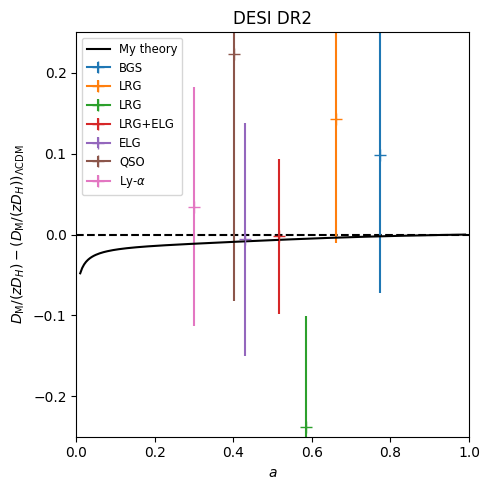

In [36]:
def theory_ratio(z):
    integral, _ = quad(lambda zp: 1/float(h_interp(zp)), 0, z)
    return float(h_interp(z)) * integral / z


# ── 5. PLOT ───────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(5, 5))
ax.axhline(0, color='k', linestyle='--')

for a, res, err, label, color in zip(a_vals, residuals, ratio_std, labels, colors):
    ax.errorbar(a, res, yerr=err, marker='+', markersize=8, linewidth=1.5,
                color=color, label=label, capsize=0)

a_plot = np.linspace(0.01, 0.99, 200)
z_plot = 1 / a_plot - 1
theory_res = np.array([theory_ratio(z) - lcdm_ratio(z) for z in z_plot])
ax.plot(a_plot, theory_res, color='k', linewidth=1.5, label='My theory')

ax.set(
    xlabel=r'$a$',
    ylabel=r'$D_\mathrm{M}/(zD_H) - (D_\mathrm{M}/(zD_H))_{\Lambda\mathrm{CDM}}$',
    xlim=(0, 1),
    ylim=(-0.25, 0.25),
    title='DESI DR2',
)
ax.legend(fontsize='small')
fig.tight_layout()

In [22]:
print(f"ΛCDM best fit H0rd: {h0rd_bf:.2f}")     
print(f"Theory H0rd:        {h0rd_theory:.2f}") 

ΛCDM best fit H0rd: 10157.46
Theory H0rd:        10240.44
